<a href="https://colab.research.google.com/github/hackwithhavk/QuantitativeFinance/blob/main/Lab%20Notebooks/Srujana/Quantitative_Finance_SEC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import requests
import zipfile
from google.colab import userdata
import pandas as pd

my_user_agent = userdata.get('SEC_USER_AGENT')

url = "https://www.sec.gov/files/dera/data/financial-statement-data-sets/2026q3.zip"
headers = {"User-Agent": my_user_agent}

response = requests.get(url, headers=headers, stream=True)

if response.status_code == 200:
    with open("2026q3.zip", "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    print("Download complete")
else:
    print(f"Failed to download. Status code: {response.status_code}")

Download complete


In [8]:
with zipfile.ZipFile("2026q3.zip", 'r') as zip_ref:
    zip_ref.extractall()
print("Extraction complete! You should now see SUB.txt and NUM.txt in the file browser.")

Extraction complete! You should now see SUB.txt and NUM.txt in the file browser.


In [9]:
sub_df = pd.read_csv('sub.txt', sep='\t', low_memory=False)

# for 10-K / 10-Q filings
cols_to_keep_sub = ['adsh', 'name', 'cik', 'sic', 'form']
existing_cols_sub = [c for c in cols_to_keep_sub if c in sub_df.columns]
sub_df = sub_df[existing_cols_sub]

sub_df = sub_df[sub_df['form'].isin(['10-K', '10-Q'])]
print(f"Loaded {len(sub_df):,} target filings from sub.txt.")

Loaded 5,607 target filings from sub.txt.


In [10]:
num_df = pd.read_csv('num.txt', sep='\t', low_memory=False)

cols_to_keep_num = ['adsh', 'tag', 'version', 'ddate', 'qtrs', 'uom', 'value']
existing_cols_num = [c for c in cols_to_keep_num if c in num_df.columns]
num_df = num_df[existing_cols_num]

print(f"Loaded {len(num_df):,} raw facts from num.txt.")

Loaded 3,905,397 raw facts from num.txt.


In [11]:
import gc

merged_df = pd.merge(num_df, sub_df, on='adsh', how='inner')
print(f"Total matched facts: {len(merged_df):,}")


del num_df
del sub_df
gc.collect()

Total matched facts: 3,389,165


0

In [12]:
merged_df['ddate'] = pd.to_datetime(merged_df['ddate'], format='%Y%m%d', errors='coerce')

output_path = '2026_q3_financials_clean.parquet'
print(f"Exporting to {output_path}...")


merged_df.to_parquet(output_path, engine='pyarrow', compression='snappy')
print("File ready.")

display(merged_df.head())

Exporting to 2026_q3_financials_clean.parquet...
File ready.


,adsh,tag,version,ddate,qtrs,uom,value,name,cik,sic,form
0,0000002488-26-000123,AccountsPayableCurrent,us-gaap/2026,2025-12-31,0,USD,2.929000e+09,ADVANCED MICRO DEVICES INC,2488,3674.0,10-Q
1,0000002488-26-000123,AccountsPayableCurrent,us-gaap/2026,2026-06-30,0,USD,5.359000e+09,ADVANCED MICRO DEVICES INC,2488,3674.0,10-Q
2,0000002488-26-000123,AccountsReceivableNetCurrent,us-gaap/2026,2025-12-31,0,USD,6.315000e+09,ADVANCED MICRO DEVICES INC,2488,3674.0,10-Q
3,0000002488-26-000123,AccountsReceivableNetCurrent,us-gaap/2026,2026-06-30,0,USD,7.281000e+09,ADVANCED MICRO DEVICES INC,2488,3674.0,10-Q
4,0000002488-26-000123,AccruedLiabilitiesCurrentAndNoncurrent,us-gaap/2026,2025-12-31,0,USD,5.250000e+09,ADVANCED MICRO DEVICES INC,2488,3674.0,10-Q


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

/tmp/ipykernel_509/1526094030.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=merged_df, x='form', palette='Blues')


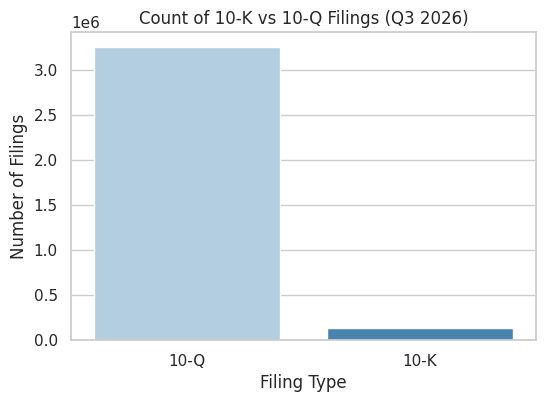

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(data=merged_df, x='form', palette='Blues')

plt.title('Count of 10-K vs 10-Q Filings (Q3 2026)')
plt.xlabel('Filing Type')
plt.ylabel('Number of Filings')
plt.show()

/tmp/ipykernel_509/321718977.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_assets, x='value', y='name', palette='viridis')


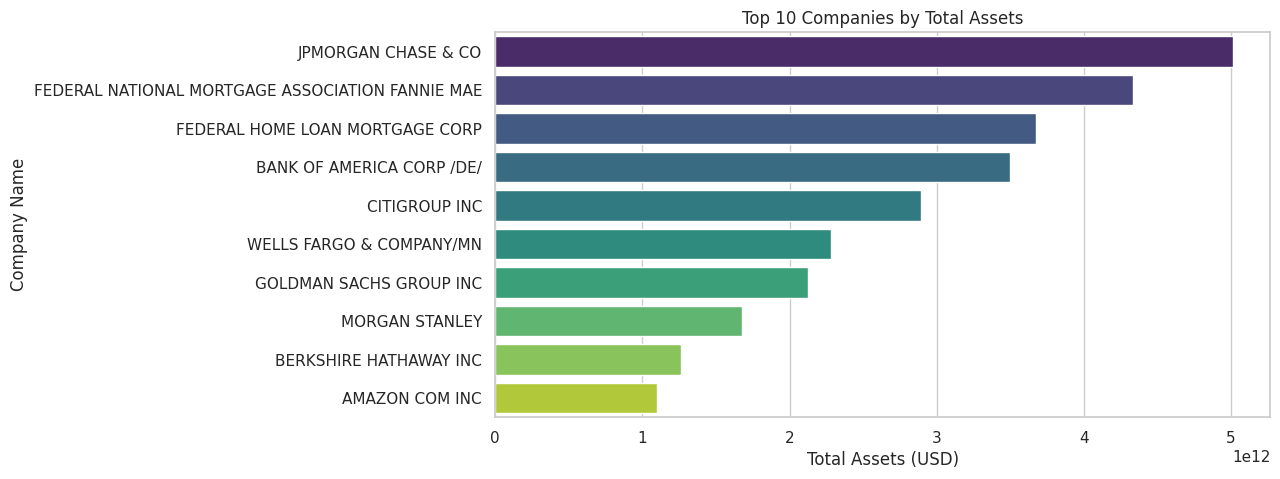

In [15]:
assets_df = merged_df[merged_df['tag'] == 'Assets'].copy()

# Sort by value to find the biggest companies and take the top 10
top_10_assets = assets_df.sort_values(by='value', ascending=False).drop_duplicates(subset=['name']).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10_assets, x='value', y='name', palette='viridis')

plt.title('Top 10 Companies by Total Assets')
plt.xlabel('Total Assets (USD)')
plt.ylabel('Company Name')
plt.show()

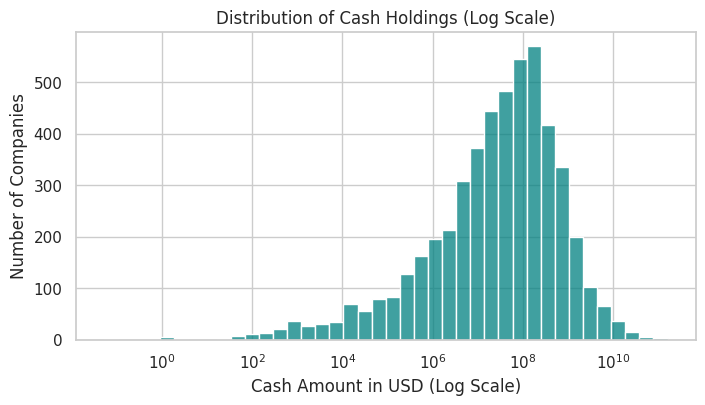

In [16]:
cash_df = merged_df[merged_df['tag'].str.contains('Cash', na=False, case=False)].copy()
cash_unique = cash_df.drop_duplicates(subset=['name'])

plt.figure(figsize=(8, 4))
sns.histplot(cash_unique['value'], bins=40, log_scale=True, color='teal')

plt.title('Distribution of Cash Holdings (Log Scale)')
plt.xlabel('Cash Amount in USD (Log Scale)')
plt.ylabel('Number of Companies')
plt.show()